# 03 — Rekonstruksi Citra
`bitwise_and` antara **citra praproses (01)** dan **mask (02)** → latar menjadi 0 (hitam), hanya objek daun yang tersisa.

Output: `output/03_rekonstruksi/<kelas>/` (di dalam folder kelasnya) + `output/manifest.csv` (label diambil dari **nama subfolder**).

In [1]:
from pathlib import Path
import json, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Root proyek = folder pcv_bkpm (otomatis, baik dijalankan dari notebooks/ maupun root)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "dataset_crop"      # input: citra daun hasil crop, 1 subfolder = 1 kelas
OUT  = ROOT / "output"            # semua hasil notebook disimpan di sini
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASSES = sorted(p.name for p in DATA.iterdir() if p.is_dir())   # label = nama subfolder

def imread(path, flags=cv2.IMREAD_COLOR):          # aman untuk path Windows ber-spasi/non-ASCII
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), flags)

def imwrite(path, img):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img); buf.tofile(str(path)); return ok

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("ROOT   :", ROOT)
print("Kelas  :", CLASSES)

ROOT   : D:\SEMESTER 5\pcv_bkpm
Kelas  : ['bercak_daun', 'sehat', 'ulat', 'virus_gemini']


c:\Users\Shobri\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
IN_PRE    = OUT / "01_praproses"
IN_MASK   = OUT / "02_mask"
OUT_RECON = OUT / "03_rekonstruksi"

# Pastikan tiap citra praproses punya pasangan mask
rows = []
for c in CLASSES:
    pre = {p.stem for p in list_images(IN_PRE / c)}
    msk = {p.stem for p in list_images(IN_MASK / c)}
    rows.append({"kelas": c, "praproses": len(pre), "mask": len(msk), "tanpa_mask": len(pre - msk)})
df_chk = pd.DataFrame(rows); display(df_chk)
assert df_chk.tanpa_mask.sum() == 0, "Ada citra tanpa mask - jalankan ulang notebook 02."

,kelas,praproses,mask,tanpa_mask
0,bercak_daun,50,50,0
1,sehat,50,50,0
2,ulat,50,50,0
3,virus_gemini,90,90,0


## 1. Demo `bitwise_and` pada 1 citra

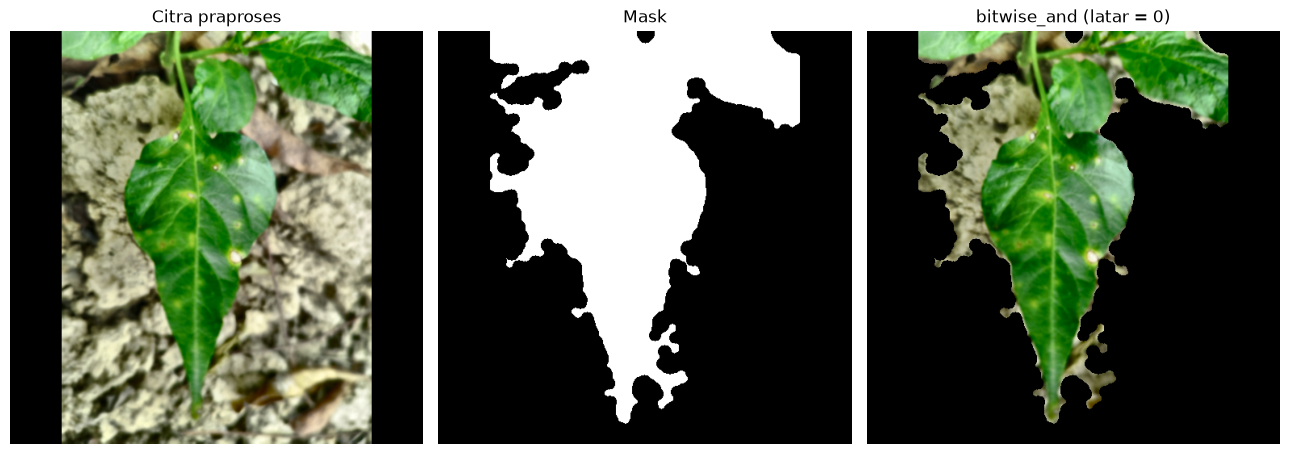

Piksel latar bernilai 0 semua: True


In [3]:
def reconstruct(img_bgr, mask):
    return cv2.bitwise_and(img_bgr, img_bgr, mask=mask)

DEMO_CLASS = "bercak_daun" if "bercak_daun" in CLASSES else CLASSES[0]
p = list_images(IN_PRE / DEMO_CLASS)[0]
im = imread(p); mk = imread(IN_MASK / DEMO_CLASS / (p.stem + ".png"), cv2.IMREAD_GRAYSCALE)
rec = reconstruct(im, mk)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, x, t in zip(axes, [rgb(im), mk, rgb(rec)], ["Citra praproses", "Mask", "bitwise_and (latar = 0)"]):
    ax.imshow(x, cmap="gray" if x.ndim == 2 else None); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()
print("Piksel latar bernilai 0 semua:", bool((rec[mk == 0] == 0).all()))

## 2. Proses seluruh dataset → `output/03_rekonstruksi/<kelas>/`

In [4]:
records = []
for c in CLASSES:
    for p in tqdm(list_images(IN_PRE / c), desc=c):
        im = imread(p); mk = imread(IN_MASK / c / (p.stem + ".png"), cv2.IMREAD_GRAYSCALE)
        rec = reconstruct(im, mk)
        out_path = OUT_RECON / c / (p.stem + ".png")
        imwrite(out_path, rec)
        records.append({
            "path_recon": out_path.relative_to(ROOT).as_posix(),
            "path_mask": (IN_MASK / c / (p.stem + ".png")).relative_to(ROOT).as_posix(),
            "label_name": c,                       # label = nama subfolder
            "obj_ratio": float((mk > 0).mean()),
        })
df_man = pd.DataFrame(records)
display(df_man.groupby("label_name").agg(jumlah=("path_recon", "count"), obj_ratio_mean=("obj_ratio", "mean"),
                                         obj_ratio_min=("obj_ratio", "min")).round(3))

virus_gemini: 100%|██████████| 90/90 [00:02<00:00, 34.11it/s]


,jumlah,obj_ratio_mean,obj_ratio_min
label_name,,,
bercak_daun,50,0.353,0.153
sehat,50,0.363,0.172
ulat,50,0.381,0.114
virus_gemini,90,0.278,0.092


## 3. Labeling otomatis dari nama subfolder

In [5]:
label_map = {name: i for i, name in enumerate(CLASSES)}      # urut alfabet, konsisten di semua notebook
df_man["label_id"] = df_man.label_name.map(label_map)
df_man.to_csv(OUT / "manifest.csv", index=False)
(OUT / "label_map.json").write_text(json.dumps(label_map, indent=2, ensure_ascii=False), encoding="utf-8")

print("Label map:", label_map)
display(df_man.sample(5, random_state=SEED))
print("Tersimpan:", OUT / "manifest.csv", "dan", OUT / "label_map.json")

Label map: {'bercak_daun': 0, 'sehat': 1, 'ulat': 2, 'virus_gemini': 3}


,path_recon,path_mask,label_name,obj_ratio,label_id
24,output/03_rekonstruksi/bercak_daun/IMG_2026110...,output/02_mask/bercak_daun/IMG_20261108_162345...,bercak_daun,0.193993,0
6,output/03_rekonstruksi/bercak_daun/IMG_2026110...,output/02_mask/bercak_daun/IMG_20261108_154406...,bercak_daun,0.292480,0
93,output/03_rekonstruksi/sehat/WhatsApp Image 20...,output/02_mask/sehat/WhatsApp Image 2026-11-08...,sehat,0.275875,1
109,output/03_rekonstruksi/ulat/IMG_20261108_16043...,output/02_mask/ulat/IMG_20261108_160436_ulat_0...,ulat,0.364990,2
104,output/03_rekonstruksi/ulat/images (3).png,output/02_mask/ulat/images (3).png,ulat,0.642303,2


Tersimpan: D:\SEMESTER 5\pcv_bkpm\output\manifest.csv dan D:\SEMESTER 5\pcv_bkpm\output\label_map.json


## 4. Preview per kelas

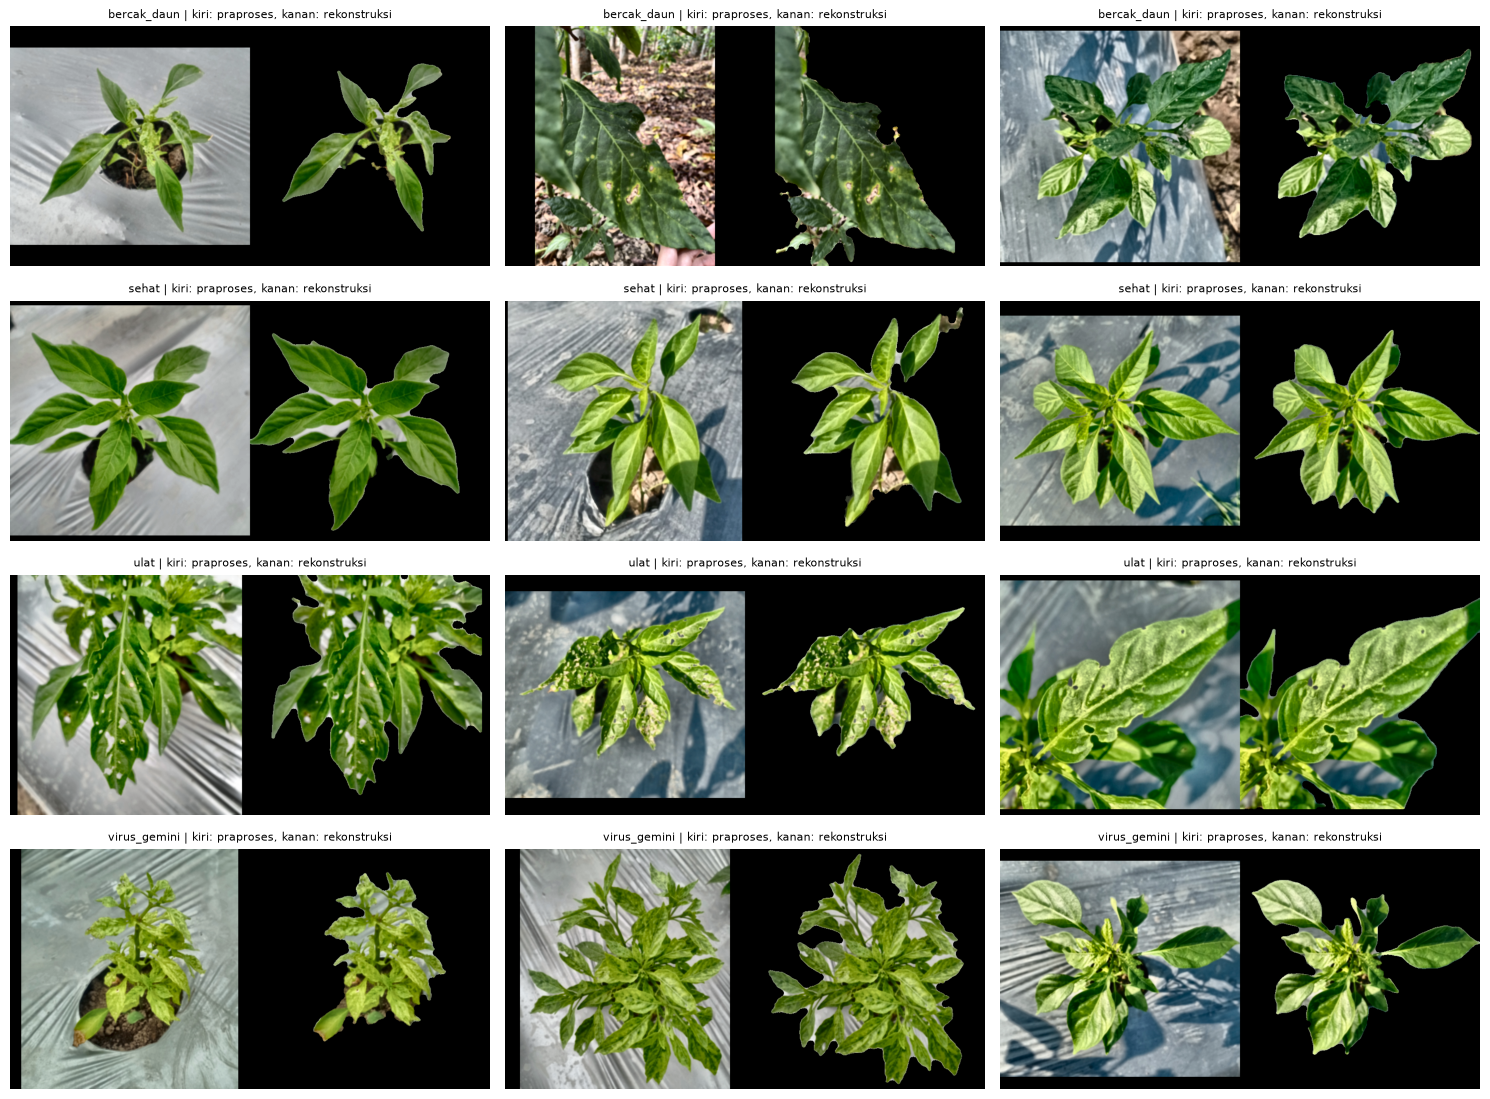

In [6]:
N_PREVIEW = 3
rng = random.Random(SEED)
fig, axes = plt.subplots(len(CLASSES), N_PREVIEW, figsize=(5 * N_PREVIEW, 2.8 * len(CLASSES)))
axes = np.atleast_2d(axes)
for i, c in enumerate(CLASSES):
    sub = df_man[df_man.label_name == c]
    for j, (_, r) in enumerate(sub.sample(min(N_PREVIEW, len(sub)), random_state=SEED).iterrows()):
        pre = imread(IN_PRE / c / (Path(r.path_recon).stem + ".png"))
        rec = imread(ROOT / r.path_recon)
        axes[i, j].imshow(rgb(np.hstack([pre, rec])))
        axes[i, j].set_title(f"{c} | kiri: praproses, kanan: rekonstruksi", fontsize=8)
    for j in range(N_PREVIEW): axes[i, j].axis("off")
plt.tight_layout(); plt.show()